# Practical 08 – Gaussian Naive Bayes Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
raw = load_iris(as_frame=True)


In [2]:
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, average='macro'), 'Recall': recall_score(y_test, pred, average='macro'), 'F1': f1_score(y_test, pred, average='macro')}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=raw.target_names))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=raw.target_names, cmap='Blues')
    plt.title(name)
    plt.show()
    return scores


Gaussian Naive Bayes {'Accuracy': 0.9666666666666667, 'Precision': 0.9696969696969697, 'Recall': 0.9666666666666667, 'F1': 0.9665831244778612}
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



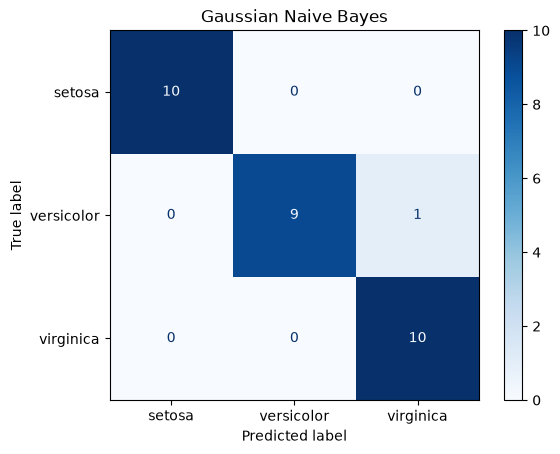

First five class probabilities:
 [[1.00000000e+000 2.10423610e-020 1.24046690e-025]
 [8.47878473e-143 8.77457913e-002 9.12254209e-001]
 [2.60594992e-036 9.99999490e-001 5.10180517e-007]
 [1.34650506e-036 9.99999567e-001 4.32500853e-007]
 [1.00000000e+000 6.60692071e-021 6.79224134e-026]]


In [4]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
evaluate('Gaussian Naive Bayes', model)
print('First five class probabilities:\n', model.predict_proba(X_test.iloc[:5]))
